In [1]:
# --- Setup (works locally and in Google Colab) ---
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("src").exists():
    !git clone https://github.com/ArjunGopal10/privacy-preserving-synthetic-graph-generation.git
    %cd privacy-preserving-synthetic-graph-generation
    !pip install -q -r requirements.txt
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from src.visualization.plot_style import apply_style
apply_style(); plt.rcParams["figure.dpi"] = 100
%matplotlib inline

# 03 · Privacy metrics
Only $\varepsilon$ and $p$ are **formal** DP quantities. Precision, recall, F1, Jaccard, retention and density are **empirical indicators** computed against the known original graph.

In [2]:
from src.graph_generation.graph_loader import load_karate_club
from src.privacy.privacy_analysis import sweep_privacy, privacy_budget_table
G = load_karate_club()
per, summ = sweep_privacy(G, [0.1, 0.5, 1, 2, 3, 5, 8], n_releases=20, seed=42)
summ[["epsilon", "flip_fraction_mean", "precision_mean", "precision_analytic", "recall_mean", "f1_mean", "jaccard_mean", "retention_mean"]].round(3)

,epsilon,flip_fraction_mean,precision_mean,precision_analytic,recall_mean,f1_mean,jaccard_mean,retention_mean
0,0.1,0.476,0.151,0.151,0.522,0.234,0.133,0.522
1,0.5,0.379,0.210,0.210,0.620,0.313,0.186,0.620
2,1.0,0.272,0.304,0.305,0.741,0.431,0.275,0.741
3,2.0,0.118,0.550,0.544,0.887,0.678,0.514,0.887
4,3.0,0.048,0.762,0.764,0.953,0.846,0.734,0.953
5,5.0,0.007,0.953,0.960,0.997,0.975,0.951,0.997
6,8.0,0.000,0.999,0.998,1.000,0.999,0.999,1.000


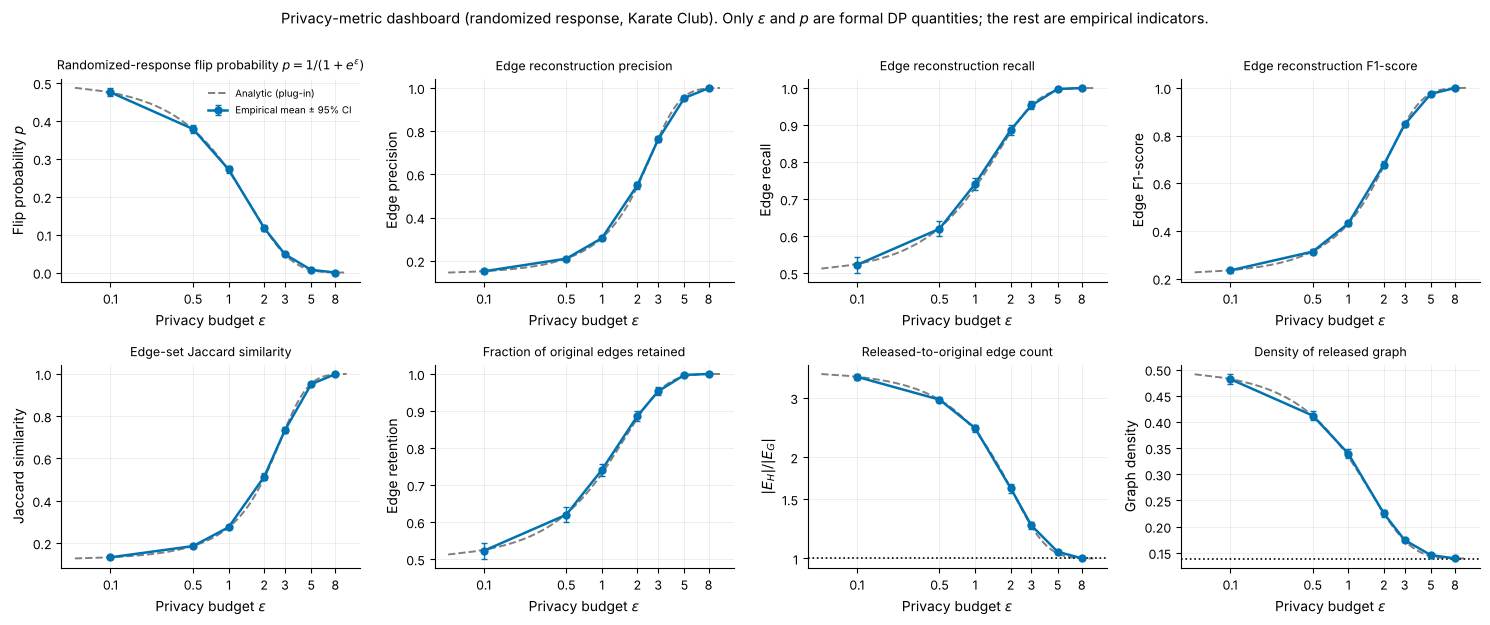

In [3]:
from src.visualization.privacy_plots import dense_analytic, fig_dashboard
fig, _ = fig_dashboard(summ, dense_analytic(561, 78), 78 / 561); plt.show()

In [4]:
privacy_budget_table([0.1, 0.5, 1, 2, 3, 5, 8], 561, 78).round(3)

,epsilon,flip_probability,likelihood_ratio_bound_exp_eps,verified_max_log_likelihood_ratio,prior_edge_probability,posterior_belief_observed_edge,posterior_belief_observed_non_edge,total_epsilon_1_releases,total_epsilon_2_releases,total_epsilon_5_releases,total_epsilon_10_releases
0,0.1,0.475,1.105,0.1,0.139,0.151,0.127,0.1,0.2,0.5,1.0
1,0.5,0.378,1.649,0.5,0.139,0.210,0.089,0.5,1.0,2.5,5.0
2,1.0,0.269,2.718,1.0,0.139,0.305,0.056,1.0,2.0,5.0,10.0
3,2.0,0.119,7.389,2.0,0.139,0.544,0.021,2.0,4.0,10.0,20.0
4,3.0,0.047,20.086,3.0,0.139,0.764,0.008,3.0,6.0,15.0,30.0
5,5.0,0.007,148.413,5.0,0.139,0.960,0.001,5.0,10.0,25.0,50.0
6,8.0,0.000,2980.958,8.0,0.139,0.998,0.000,8.0,16.0,40.0,80.0
